CREAR ENTRADA PARA EL MODELO: BBDD a ifn3_ifn4.csv

Trabajamos solo con inventario = 3.

La PK del CSV será parcela_id_especie = CONCAT(parcela_id, '_', especie).

Partimos de parcela_inventario_especie (inv=3) y sacamos: parcela_id, especie, ocupa, estado, fpmasa, tratmasa, orgmasa1.

Añadimos de parcelas: presencia, tipsuelo1, tipsuelo2, tipsuelo3, rocosidad, radio.

Añadimos de especies: conif_fronf, especie_grupo.

Añadimos de parcela_inventario (inv=3): ano, merosiva, textura, matorg, modcomb, disesp, comesp, fccarb, fcctot (un registro por parcela_id e inventario).

Añadimos de parcela_inventario_especie_cd (inv=3):

npies en formato ancho por cd → columnas npies_{cd}

ca y cr como sumas por parcela_especie (agregadas sobre todos los cd).

El CSV final queda a nivel de parcela_especie.

In [1]:
# -*- coding: utf-8 -*-
from db import engine
import pandas as pd
from sqlalchemy import text
from datetime import datetime

# =========================
# CONFIG
# =========================
OUT_CSV = "bbdd/ifn3.csv"


# =========================
# 1) Base: parcela_inventario_especie (inv=3)
# =========================
with engine.connect() as conn:
    pie3 = pd.read_sql(text("""
        SELECT 
            parcela_id,
            especie_id,  
            ocupa,
            estado_id,
            fpmasa_id,
            tratmasa_id,
            orgmasa1_id
        FROM parcela_inventario_especie
        WHERE inventario_id = 3
    """), conn)

# Clave primaria del CSV (parcela + especie)
pie3["parcela_id"] = pie3["parcela_id"].astype(str).str.strip()
pie3["especie_id"] = pd.to_numeric(pie3["especie_id"], errors="coerce").astype("Int64")
pie3["idparcela_especie"] = pie3["parcela_id"] + "_" + pie3["especie_id"].astype(str)

# En caso de duplicados (mismo idparcela_especie), nos quedamos con la primera
pie3 = pie3.drop_duplicates(subset=["idparcela_especie"], keep="first")

# =========================
# 2) parcelas (atributos por parcela_id)
# =========================
with engine.connect() as conn:
    parcelas = pd.read_sql(text("""
        SELECT 
            parcela_id,
            tipsuelo1_id,
            tipsuelo2_id,
            tipsuelo3_id,
            rocosidad_id,
            radio,
            orientacion,
            elevacion,
            pendiente,
            martonneidx_id
        FROM parcelas
    """), conn)
parcelas["parcela_id"] = parcelas["parcela_id"].astype(str).str.strip()

# =========================
# 3) especies (+ grupos) (atributos por especie_id)
# =========================
with engine.connect() as conn:
    especies = pd.read_sql(text("""
        SELECT 
            e.especie_id,
            e.tipo_especie,
            e.grupo_id,
            g.nombregrupo AS grupo_nombre
        FROM especies e
        LEFT JOIN grupos g ON g.grupo_id = e.grupo_id
    """), conn)
especies["especie_id"] = pd.to_numeric(especies["especie_id"], errors="coerce").astype("Int64")

# =========================
# 4) parcela_inventario (inv=3) por parcela_id
# =========================
with engine.connect() as conn:
    pi3 = pd.read_sql(text("""
        SELECT 
            parcela_id, 
            inventario_id, 
            ano,
            nivel1_id, 
            nivel2_id,
            merosiva_id, 
            textura_id,
            matorg_id, 
            modcomb_id,
            disesp_id,
            comesp_id,
            fccarb,
            fcctot
        FROM parcela_inventario
        WHERE inventario_id = 3
    """), conn)

pi3["parcela_id"] = pi3["parcela_id"].astype(str).str.strip()
# 1 fila por parcela_id en inv=3 (si existiera más de una, conservamos la primera)
pi3 = pi3.drop_duplicates(subset=["parcela_id"], keep="first")

# =========================
# 5) parcela_inventario_especie_cd (inv=3) → pivot npies_{cd}, sumas de ca/cr y carbono_bruto3
# =========================
with engine.connect() as conn:
    cd3 = pd.read_sql(text("""
        SELECT parcela_id, especie_id, cd_id, npies, ca, cr, carbono_bruto
        FROM parcela_inventario_especie_cd
        WHERE inventario_id = 3
    """), conn)

cd3["parcela_id"] = cd3["parcela_id"].astype(str).str.strip()
cd3["especie_id"] = pd.to_numeric(cd3["especie_id"], errors="coerce").astype("Int64")
cd3["cd_id"]      = pd.to_numeric(cd3["cd_id"], errors="coerce").astype("Int64")

# Solo pares (parcela_id, especie_id) presentes en la base pie3
key_set = set(pie3[["parcela_id","especie_id"]].itertuples(index=False, name=None))
cd3 = cd3[cd3.set_index(["parcela_id","especie_id"]).index.isin(key_set)].copy()

# npies ancho por cd_id
npies_wide = (
    cd3.pivot_table(
        index=["parcela_id", "especie_id"],
        columns="cd_id",
        values="npies",
        aggfunc="sum",
        fill_value=0.0,
    )
)
npies_wide.columns = [f"npies_{int(c)}" for c in npies_wide.columns]
npies_wide = npies_wide.reset_index()

# Sumatorios de ca, cr y carbono_bruto (→ carbono_bruto3)
cacr_cb = (
    cd3.groupby(["parcela_id","especie_id"], as_index=False)
       .agg(
           ca=("ca", lambda s: s.sum(min_count=1)),
           cr=("cr", lambda s: s.sum(min_count=1)),
           carbono_bruto3=("carbono_bruto", lambda s: s.sum(min_count=1)),
       )
)

# Merge de ambos (npies ancho + sumas ca/cr + carbono_bruto3)
cd_agg = pd.merge(npies_wide, cacr_cb, on=["parcela_id","especie_id"], how="outer")

# =========================
# 6) Integración de todo al nivel idparcela_especie
# =========================
base = pie3.copy()

# + parcelas
base = base.merge(parcelas, on="parcela_id", how="left")

# + especies (+ grupos)
base = base.merge(especies, on="especie_id", how="left")

# + parcela_inventario (inv=3) por parcela_id
base = base.merge(pi3.drop(columns=["inventario_id"]), on="parcela_id", how="left")

# + cd agregados (npies_{cd}, ca, cr, carbono_bruto3)
base = base.merge(cd_agg, on=["parcela_id","especie_id"], how="left")

# Recalcular PK textual por claridad
base["idparcela_especie"] = base["parcela_id"] + "_" + base["especie_id"].astype(str)

# =========================
# 7) Orden de columnas (PK + campos fijos + dinámicas npies_* + ca/cr/carbono_bruto3)
# =========================
cols_fijas = [
    "idparcela_especie","parcela_id", "especie_id",
    # atributos de especie/grupo
    "tipo_especie", "grupo_id",
    # atributos del registro especie en la parcela/inventario
    "ocupa", "estado_id", "fpmasa_id", "tratmasa_id", "orgmasa1_id",
    # atributos de la parcela
    "tipsuelo1_id", "tipsuelo2_id", "tipsuelo3_id", "rocosidad_id", "radio",
    "orientacion","elevacion","pendiente","martonneidx_id",
    # atributos de parcela_inventario (inv=3)
    "ano", "nivel1_id", "nivel2_id",
    "merosiva_id", "textura_id", "matorg_id", "modcomb_id", "disesp_id", "comesp_id",
    "fccarb", "fcctot",
]
cols_npies = sorted(
    [c for c in base.columns if c.startswith("npies_")],
    key=lambda x: int(x.split("_")[1]) if x.split("_")[1].isdigit() else 10**9
)
cols_fijas_existentes = [c for c in cols_fijas if c in base.columns]
cols_final = cols_fijas_existentes + cols_npies + [c for c in ["ca","cr","carbono_bruto3"] if c in base.columns]

df_final = base[cols_final].copy()

# =========================
# 8) Exportar CSV
# =========================
df_final.to_csv(OUT_CSV, index=False, encoding="utf-8")
print(f"✅ CSV generado: {OUT_CSV}")
print(f"   Filas: {len(df_final):,} | Columnas: {len(df_final.columns):,}")

# Vista previa
print("\n🔎 Vista previa:")
print(df_final.head(10))


✅ CSV generado: bbdd/ifn3.csv
   Filas: 119,864 | Columnas: 49

🔎 Vista previa:
  idparcela_especie parcela_id  especie_id  tipo_especie grupo_id  ocupa  \
0          01_03_41      01_03          41           1.0     None    3.0   
1          01_03_44      01_03          44           1.0     None    2.0   
2          01_03_72      01_03          72           1.0     None    6.0   
3          01_03_92      01_03          92           1.0     None    NaN   
4         01_03_215      01_03         215           1.0     None    NaN   
5           01_05_2      01_05           2           1.0     None    NaN   
6          01_05_28      01_05          28           0.0     None    5.0   
7          01_05_43      01_05          43           1.0     None    5.0   
8          01_09_28      01_09          28           0.0     None    3.0   
9          01_09_41      01_09          41           1.0     None    5.0   

   estado_id  fpmasa_id  tratmasa_id  orgmasa1_id  ...  npies_40  npies_45  \
0    

ANALOGO IFN4

In [2]:
# -*- coding: utf-8 -*-
from db import engine
import pandas as pd
from sqlalchemy import text
from datetime import datetime

# =========================
# CONFIG
# =========================
OUT_CSV = "bbdd/ifn4.csv"


# =========================
# 1) Base: parcela_inventario_especie (inv=4)
# =========================
with engine.connect() as conn:
    pie3 = pd.read_sql(text("""
        SELECT 
            parcela_id,
            especie_id,  
            ocupa,
            estado_id,
            fpmasa_id,
            tratmasa_id,
            orgmasa1_id
        FROM parcela_inventario_especie
        WHERE inventario_id = 4
    """), conn)

# Clave primaria del CSV (parcela + especie)
pie3["parcela_id"] = pie3["parcela_id"].astype(str).str.strip()
pie3["especie_id"] = pd.to_numeric(pie3["especie_id"], errors="coerce").astype("Int64")
pie3["idparcela_especie"] = pie3["parcela_id"] + "_" + pie3["especie_id"].astype(str)

# En caso de duplicados (mismo idparcela_especie), nos quedamos con la primera
pie3 = pie3.drop_duplicates(subset=["idparcela_especie"], keep="first")

# =========================
# 2) parcelas (atributos por parcela_id)
# =========================
with engine.connect() as conn:
    parcelas = pd.read_sql(text("""
        SELECT 
            parcela_id,
            tipsuelo1_id,
            tipsuelo2_id,
            tipsuelo3_id,
            rocosidad_id,
            radio,
            orientacion,
            elevacion,
            pendiente,
            martonneidx_id
        FROM parcelas
    """), conn)
parcelas["parcela_id"] = parcelas["parcela_id"].astype(str).str.strip()

# =========================
# 3) especies (+ grupos) (atributos por especie_id)
# =========================
with engine.connect() as conn:
    especies = pd.read_sql(text("""
        SELECT 
            e.especie_id,
            e.tipo_especie,
            e.grupo_id,
            g.nombregrupo AS grupo_nombre
        FROM especies e
        LEFT JOIN grupos g ON g.grupo_id = e.grupo_id
    """), conn)
especies["especie_id"] = pd.to_numeric(especies["especie_id"], errors="coerce").astype("Int64")

# =========================
# 4) parcela_inventario (inv=4) por parcela_id
# =========================
with engine.connect() as conn:
    pi3 = pd.read_sql(text("""
        SELECT 
            parcela_id, 
            inventario_id, 
            ano,
            nivel1_id, 
            nivel2_id,
            merosiva_id, 
            textura_id,
            matorg_id, 
            modcomb_id,
            disesp_id,
            comesp_id,
            fccarb,
            fcctot
        FROM parcela_inventario
        WHERE inventario_id = 4
    """), conn)

pi3["parcela_id"] = pi3["parcela_id"].astype(str).str.strip()
# 1 fila por parcela_id en inv=4 (si existiera más de una, conservamos la primera)
pi3 = pi3.drop_duplicates(subset=["parcela_id"], keep="first")

# =========================
# 5) parcela_inventario_especie_cd (inv=4) → pivot npies_{cd}, sumas de ca/cr y carbono_bruto4
# =========================
with engine.connect() as conn:
    cd3 = pd.read_sql(text("""
        SELECT parcela_id, especie_id, cd_id, npies, ca, cr, carbono_bruto
        FROM parcela_inventario_especie_cd
        WHERE inventario_id = 4
    """), conn)

cd3["parcela_id"] = cd3["parcela_id"].astype(str).str.strip()
cd3["especie_id"] = pd.to_numeric(cd3["especie_id"], errors="coerce").astype("Int64")
cd3["cd_id"]      = pd.to_numeric(cd3["cd_id"], errors="coerce").astype("Int64")

# Solo pares (parcela_id, especie_id) presentes en la base pie3
key_set = set(pie3[["parcela_id","especie_id"]].itertuples(index=False, name=None))
cd3 = cd3[cd3.set_index(["parcela_id","especie_id"]).index.isin(key_set)].copy()

# npies ancho por cd_id
npies_wide = (
    cd3.pivot_table(
        index=["parcela_id", "especie_id"],
        columns="cd_id",
        values="npies",
        aggfunc="sum",
        fill_value=0.0,
    )
)
npies_wide.columns = [f"npies_{int(c)}" for c in npies_wide.columns]
npies_wide = npies_wide.reset_index()

# Sumatorios de ca, cr y carbono_bruto (→ carbono_bruto4)
cacr_cb = (
    cd3.groupby(["parcela_id","especie_id"], as_index=False)
       .agg(
           ca=("ca", lambda s: s.sum(min_count=1)),
           cr=("cr", lambda s: s.sum(min_count=1)),
           carbono_bruto4=("carbono_bruto", lambda s: s.sum(min_count=1)),
       )
)

# Merge de ambos (npies ancho + sumas ca/cr + carbono_bruto4)
cd_agg = pd.merge(npies_wide, cacr_cb, on=["parcela_id","especie_id"], how="outer")

# =========================
# 6) Integración de todo al nivel idparcela_especie
# =========================
base = pie3.copy()

# + parcelas
base = base.merge(parcelas, on="parcela_id", how="left")

# + especies (+ grupos)
base = base.merge(especies, on="especie_id", how="left")

# + parcela_inventario (inv=3) por parcela_id
base = base.merge(pi3.drop(columns=["inventario_id"]), on="parcela_id", how="left")

# + cd agregados (npies_{cd}, ca, cr, carbono_bruto4)
base = base.merge(cd_agg, on=["parcela_id","especie_id"], how="left")

# Recalcular PK textual por claridad
base["idparcela_especie"] = base["parcela_id"] + "_" + base["especie_id"].astype(str)

# =========================
# 7) Orden de columnas (PK + campos fijos + dinámicas npies_* + ca/cr/carbono_bruto4)
# =========================
cols_fijas = [
    "idparcela_especie","parcela_id", "especie_id",
    # atributos de especie/grupo
    "tipo_especie", "grupo_id",
    # atributos del registro especie en la parcela/inventario
    "ocupa", "estado_id", "fpmasa_id", "tratmasa_id", "orgmasa1_id",
    # atributos de la parcela
    "tipsuelo1_id", "tipsuelo2_id", "tipsuelo3_id", "rocosidad_id", "radio",
    "orientacion","elevacion","pendiente","martonneidx_id",
    # atributos de parcela_inventario (inv=3)
    "ano", "nivel1_id", "nivel2_id",
    "merosiva_id", "textura_id", "matorg_id", "modcomb_id", "disesp_id", "comesp_id",
    "fccarb", "fcctot",
]
cols_npies = sorted(
    [c for c in base.columns if c.startswith("npies_")],
    key=lambda x: int(x.split("_")[1]) if x.split("_")[1].isdigit() else 10**9
)
cols_fijas_existentes = [c for c in cols_fijas if c in base.columns]
cols_final = cols_fijas_existentes + cols_npies + [c for c in ["ca","cr","carbono_bruto4"] if c in base.columns]

df_final = base[cols_final].copy()

# =========================
# 8) Exportar CSV
# =========================
df_final.to_csv(OUT_CSV, index=False, encoding="utf-8")
print(f"✅ CSV generado: {OUT_CSV}")
print(f"   Filas: {len(df_final):,} | Columnas: {len(df_final.columns):,}")

# Vista previa
print("\n🔎 Vista previa:")
print(df_final.head(10))


✅ CSV generado: bbdd/ifn4.csv
   Filas: 119,529 | Columnas: 49

🔎 Vista previa:
  idparcela_especie parcela_id  especie_id  tipo_especie grupo_id  ocupa  \
0          01_03_28      01_03          28           0.0     None    9.0   
1          01_03_41      01_03          41           1.0     None    NaN   
2          01_03_44      01_03          44           1.0     None    2.0   
3          01_03_65      01_03          65           1.0     None    NaN   
4          01_03_72      01_03          72           1.0     None    7.0   
5          01_03_74      01_03          74           1.0     None    NaN   
6         01_03_215      01_03         215           1.0     None    NaN   
7         01_03_273      01_03         273           1.0     None    NaN   
8          01_05_28      01_05          28           0.0     None    4.0   
9          01_05_41      01_05          41           1.0     None    NaN   

   estado_id  fpmasa_id  tratmasa_id  orgmasa1_id  ...   npies_40   npies_45  \
0  

unificamos
Tomar IFN3 como tabla base (join por idparcela_especie con IFN4).

Renombrar y derivar en IFN3: ano3 = ano, ca3 = ca, cr3 = cr, c3 = ca3 + cr3.

Renombrar y derivar en IFN4: ano4 = ano, cr4 = cr, c4 = ca4 + cr4 (usando ca de IFN4 como ca4, pero no lo incluyo en el CSV final).

Conservar exactamente las columnas de IFN3 que pides (incluyendo todos los npies_*).

Añadir de IFN4 solo ano4, cr4, c4.

Hacer left join (IFN3 → IFN4) para no perder filas que existan solo en IFN3.

Rellenar faltantes numéricos con NaN (no 0) salvo los npies_* que dejaremos como están (si no existen, los creo con NaN).

In [3]:
# -*- coding: utf-8 -*-
import pandas as pd
from pathlib import Path

# Rutas
ruta_ifn3 = Path("bbdd/ifn3.csv")
ruta_ifn4 = Path("bbdd/ifn4.csv")
ruta_out  = Path("bbdd/ifn3_ifn4.csv")

# === 1) Cargar CSVs ===
df3 = pd.read_csv(ruta_ifn3)
df4 = pd.read_csv(ruta_ifn4)

# Normalizar PK esperada
for df in (df3, df4):
    if "idparcela_especie" not in df.columns:
        if {"parcela_id","especie_id"}.issubset(df.columns):
            df["parcela_id"] = df["parcela_id"].astype(str).str.strip()
            df["especie_id"] = pd.to_numeric(df["especie_id"], errors="coerce").astype("Int64")
            df["idparcela_especie"] = df["parcela_id"] + "_" + df["especie_id"].astype(str)
        else:
            raise SystemExit("No encuentro 'idparcela_especie' ni (parcela_id, especie_id) para construirla.")

# === 2) IFN3: renombrar / derivar ===
npies_cols_req = [f"npies_{v}" for v in (1,2,5,10,15,20,25,30,35,40,45,50,55,60,65,70)]
for c in npies_cols_req:
    if c not in df3.columns:
        df3[c] = pd.NA

df3["ano3"] = pd.to_numeric(df3.get("ano"), errors="coerce")
df3["ca3"]  = pd.to_numeric(df3.get("ca"), errors="coerce")
df3["cr3"]  = pd.to_numeric(df3.get("cr"), errors="coerce")
df3["c3"]   = df3["ca3"] + df3["cr3"]

# Columnas objetivo con nomenclatura *_id
cols_ifn3_final = [
    "idparcela_especie",
    "parcela_id",
    "especie_id",
    # especie/grupo
    "tipo_especie", "grupo_id",
    # registro especie en parcela
    "ocupa", "estado_id", "fpmasa_id", "tratmasa_id", "orgmasa1_id",
    # atributos de parcela
    "tipsuelo1_id", "tipsuelo2_id", "tipsuelo3_id", "rocosidad_id", "radio",'orientacion','elevacion','pendiente',"martonneidx_id",
    # atributos de parcela_inventario (inv=3)
    "ano3", "nivel1_id", "nivel2_id",
    "merosiva_id", "textura_id", "matorg_id", "modcomb_id", "disesp_id", "comesp_id",
    "fccarb", "fcctot",
    'carbono_bruto3',
] + npies_cols_req + [
    "ca3","cr3","c3"
]

# Reindex con relleno si falta alguna (por robustez)
df3_sel = df3.reindex(columns=cols_ifn3_final, fill_value=pd.NA)

# === 3) IFN4: derivar (solo 3 campos de salida) ===
df4["ano4"] = pd.to_numeric(df4.get("ano"), errors="coerce")
ca4 = pd.to_numeric(df4.get("ca"), errors="coerce")
df4["cr4"]  = pd.to_numeric(df4.get("cr"), errors="coerce")
df4["c4"]   = ca4 + df4["cr4"]

df4_sel = df4[["idparcela_especie","ano4","cr4","c4",'carbono_bruto4']].copy()

# === 4) Merge IFN3 (base) + IFN4 (left join por idparcela_especie) ===
df_out = df3_sel.merge(df4_sel, on="idparcela_especie", how="left")

# === 5) Crear variable 'periodo' ===
df_out["periodo"] = df_out["ano4"] - df_out["ano3"]

# === 6) Guardar ===
df_out.to_csv(ruta_out, index=False, encoding="utf-8")
print(f"✅ Generado: {ruta_out}")
print(f"   Filas: {len(df_out):,} | Columnas: {len(df_out.columns):,}")

# Resumen rápido
n_match = df_out["ano4"].notna().sum()
print(f"🔗 Coincidencias IFN3↔IFN4 por idparcela_especie: {n_match:,}")
print(f"📏 Periodo medio: {df_out['periodo'].mean():.2f} años (solo casos con ambos años)")


✅ Generado: bbdd/ifn3_ifn4.csv
   Filas: 119,864 | Columnas: 55
🔗 Coincidencias IFN3↔IFN4 por idparcela_especie: 92,789
📏 Periodo medio: 13.63 años (solo casos con ambos años)


añado las estacionales

In [4]:
# -*- coding: utf-8 -*-
from db import engine
import pandas as pd
from sqlalchemy import text
from pathlib import Path

# ----------------
# CONFIG
# ----------------
IN_CSV   = Path("bbdd/ifn3_ifn4.csv")
OUT_CSV  = Path("bbdd/ifn3_ifn4.csv")  # sobrescribe con las nuevas columnas
INVENTARIO_OBJETIVO = 3
ESTACIONES = ['primavera','otoño','verano','invierno']  # lista (no tuple)


# ----------------
# 1) Cargar base consolidada IFN3+IFN4
# ----------------
df = pd.read_csv(IN_CSV)
if "parcela_id" not in df.columns:
    raise SystemExit("El CSV base debe contener columna 'parcela_id'.")

# ----------------
# 2) Traer TODAS las métricas solicitadas (inv=3) desde la BBDD
# ----------------
metricas = [
          'evi_max' ,'evi_mean','evi_median','evi_min','evi_std',
          'gndvi_max',   'gndvi_mean', 'gndvi_median',    'gndvi_min',    'gndvi_std',
          'ndii_max',    'ndii_mean',  'ndii_median','ndii_min',     'ndii_std',
          'ndvi_max',    'ndvi_mean',  'ndvi_median',     'ndvi_min',     'ndvi_std',
          'pr_sum',      'pr_mean',       'pr_min',       'pr_max',       'pr_std',
          't2m_mean', 't2m_min_mean', 't2m_max_mean',
          'skt_mean', 'skt_min_mean', 'skt_max_mean',
          'stl1_mean','stl1_min_mean','stl1_max_mean',
          'stl2_mean','stl2_min_mean','stl2_max_mean',
          'stl3_mean','stl3_min_mean','stl3_max_mean',
          'stl4_mean','stl4_min_mean','stl4_max_mean',
          't2m_min',  't2m_min_min',  't2m_max_min',
          'skt_min',  'skt_min_min',  'skt_max_min',
          'stl1_min', 'stl1_min_min', 'stl1_max_min',
         'stl2_min', 'stl2_min_min', 'stl2_max_min',
          'stl3_min', 'stl3_min_min', 'stl3_max_min',
          'stl4_min', 'stl4_min_min', 'stl4_max_min',
          't2m_max',  't2m_min_max',  't2m_max_max',
          'skt_max',  'skt_min_max',  'skt_max_max',
          'stl1_max', 'stl1_min_max', 'stl1_max_max',
          'stl2_max', 'stl2_min_max', 'stl2_max_max',
          'stl3_max', 'stl3_min_max', 'stl3_max_max',
          'stl4_max', 'stl4_min_max', 'stl4_max_max',
          't2m_std',  't2m_min_std',  't2m_max_std',
          'skt_std',  'skt_min_std',  'skt_max_std',
          'stl1_std', 'stl1_min_std', 'stl1_max_std',
          'stl2_std', 'stl2_min_std', 'stl2_max_std',
          'stl3_std', 'stl3_min_std', 'stl3_max_std',
          'stl4_std', 'stl4_min_std', 'stl4_max_std',

]

# construir placeholders :e0, :e1, ...
ests_ph = ", ".join([f":e{i}" for i in range(len(ESTACIONES))])
sql = f"""
    SELECT
        parcela_id,
        inventario_id,
        estacion_id,
        {", ".join(metricas)}
    FROM parcela_inventario_estacion
    WHERE inventario_id = :inv
      AND estacion_id IN ({ests_ph})
"""

params = {"inv": INVENTARIO_OBJETIVO}
params.update({f"e{i}": est for i, est in enumerate(ESTACIONES)})

with engine.connect() as conn:
    est = pd.read_sql(text(sql), conn, params=params)

print(f"[INFO] Registros estación leídos: {len(est):,}")

# ----------------
# 3) Pivotar a ancho por estación -> <métrica>_<estacion>
# ----------------
wide = est.pivot_table(
    index=["parcela_id"],
    columns="estacion_id",
    values=metricas,
    aggfunc="first"
)

# Aplanar MultiIndex de columnas
wide.columns = [f"{m}_{s}" for (m, s) in wide.columns]
wide = wide.reset_index()

# ----------------
# 4) Merge al CSV base por parcela_id y guardar
# ----------------
df_out = df.merge(wide, on="parcela_id", how="left")
df_out.to_csv(OUT_CSV, index=False, encoding="utf-8-sig")

added_cols = [c for c in df_out.columns if any(c.startswith(f"{m}_") for m in metricas)]
print(f"✅ Actualizado: {OUT_CSV}")
print(f"➕ Columnas añadidas/pivotadas: {len(added_cols)}")
print(", ".join(added_cols[:20]) + (" ..." if len(added_cols) > 20 else ""))


[INFO] Registros estación leídos: 0


✅ Actualizado: bbdd/ifn3_ifn4.csv
➕ Columnas añadidas/pivotadas: 0



idparcela_especie,parcela_id,especie_id,tipo_especie,grupo_id,ocupa,estado_id,fpmasa_id,tratmasa_id,orgmasa1_id,tipsuelo1_id,tipsuelo2_id,tipsuelo3_id,rocosidad_id,radio,orientacion,elevacion,pendiente,ano3,nivel1_id,nivel2_id,merosiva_id,textura_id,matorg_id,modcomb_id,disesp_id,comesp_id,fccarb,fcctot,npies_1,npies_2,npies_5,npies_10,npies_15,npies_20,npies_25,npies_30,npies_35,npies_40,npies_45,npies_50,npies_55,npies_60,npies_65,npies_70,ca3,cr3,c3,ano4,cr4,c4,periodo,

evi_max_invierno,evi_max_otoño,evi_max_primavera,evi_max_verano,evi_mean_invierno,evi_mean_otoño,evi_mean_primavera,evi_mean_verano,evi_median_invierno,evi_median_otoño,evi_median_primavera,evi_median_verano,evi_min_invierno,evi_min_otoño,evi_min_primavera,evi_min_verano,evi_std_invierno,evi_std_otoño,evi_std_primavera,evi_std_verano,gndvi_max_invierno,gndvi_max_otoño,gndvi_max_primavera,gndvi_max_verano,gndvi_mean_invierno,gndvi_mean_otoño,gndvi_mean_primavera,gndvi_mean_verano,gndvi_median_invierno,gndvi_median_otoño,gndvi_median_primavera,gndvi_median_verano,gndvi_min_invierno,gndvi_min_otoño,gndvi_min_primavera,gndvi_min_verano,gndvi_std_invierno,gndvi_std_otoño,gndvi_std_primavera,gndvi_std_verano,ndii_max_invierno,ndii_max_otoño,ndii_max_primavera,ndii_max_verano,ndii_mean_invierno,ndii_mean_otoño,ndii_mean_primavera,ndii_mean_verano,ndii_median_invierno,ndii_median_otoño,ndii_median_primavera,ndii_median_verano,ndii_min_invierno,ndii_min_otoño,ndii_min_primavera,ndii_min_verano,ndii_std_invierno,ndii_std_otoño,ndii_std_primavera,ndii_std_verano,ndvi_max_invierno,ndvi_max_otoño,ndvi_max_primavera,ndvi_max_verano,ndvi_mean_invierno,ndvi_mean_otoño,ndvi_mean_primavera,ndvi_mean_verano,ndvi_median_invierno,ndvi_median_otoño,ndvi_median_primavera,ndvi_median_verano,ndvi_min_invierno,ndvi_min_otoño,ndvi_min_primavera,ndvi_min_verano,ndvi_std_invierno,ndvi_std_otoño,ndvi_std_primavera,ndvi_std_verano,pr_max_invierno,pr_max_otoño,pr_max_primavera,pr_max_verano,pr_mean_invierno,pr_mean_otoño,pr_mean_primavera,pr_mean_verano,pr_min_invierno,pr_min_otoño,pr_min_primavera,pr_min_verano,pr_std_invierno,pr_std_otoño,pr_std_primavera,pr_std_verano,pr_sum_invierno,pr_sum_otoño,pr_sum_primavera,pr_sum_verano,skt_max_invierno,skt_max_otoño,skt_max_primavera,skt_max_verano,skt_mean_invierno,skt_mean_otoño,skt_mean_primavera,skt_mean_verano,skt_min_invierno,skt_min_otoño,skt_min_primavera,skt_min_verano,skt_std_invierno,skt_std_otoño,skt_std_primavera,skt_std_verano,stl1_max_invierno,stl1_max_otoño,stl1_max_primavera,stl1_max_verano,stl1_mean_invierno,stl1_mean_otoño,stl1_mean_primavera,stl1_mean_verano,stl1_min_invierno,stl1_min_otoño,stl1_min_primavera,stl1_min_verano,stl1_std_invierno,stl1_std_otoño,stl1_std_primavera,stl1_std_verano,stl2_max_invierno,stl2_max_otoño,stl2_max_primavera,stl2_max_verano,stl2_mean_invierno,stl2_mean_otoño,stl2_mean_primavera,stl2_mean_verano,stl2_min_invierno,stl2_min_otoño,stl2_min_primavera,stl2_min_verano,stl2_std_invierno,stl2_std_otoño,stl2_std_primavera,stl2_std_verano,stl3_max_invierno,stl3_max_otoño,stl3_max_primavera,stl3_max_verano,stl3_mean_invierno,stl3_mean_otoño,stl3_mean_primavera,stl3_mean_verano,stl3_min_invierno,stl3_min_otoño,stl3_min_primavera,stl3_min_verano,stl3_std_invierno,stl3_std_otoño,stl3_std_primavera,stl3_std_verano,stl4_max_invierno,stl4_max_otoño,stl4_max_primavera,stl4_max_verano,stl4_mean_invierno,stl4_mean_otoño,stl4_mean_primavera,stl4_mean_verano,stl4_min_invierno,stl4_min_otoño,stl4_min_primavera,stl4_min_verano,stl4_std_invierno,stl4_std_otoño,stl4_std_primavera,stl4_std_verano,t2m_max_invierno,t2m_max_otoño,t2m_max_primavera,t2m_max_verano,t2m_mean_invierno,t2m_mean_otoño,t2m_mean_primavera,t2m_mean_verano,t2m_min_invierno,t2m_min_otoño,t2m_min_primavera,t2m_min_verano,t2m_std_invierno,t2m_std_otoño,t2m_std_primavera,t2m_std_verano



------------------
IFN2

In [5]:
# -*- coding: utf-8 -*-
from db import engine
import pandas as pd
from sqlalchemy import text
from datetime import datetime

# =========================
# CONFIG
# =========================
OUT_CSV = "bbdd/ifn2.csv"


# =========================
# 1) Base: parcela_inventario_especie (inv=2)
# =========================
with engine.connect() as conn:
    pie3 = pd.read_sql(text("""
        SELECT 
            parcela_id,
            especie_id,  
            ocupa,
            estado_id,
            fpmasa_id,
            tratmasa_id,
            orgmasa1_id
        FROM parcela_inventario_especie
        WHERE inventario_id = 2
    """), conn)

# Clave primaria del CSV (parcela + especie)
pie3["parcela_id"] = pie3["parcela_id"].astype(str).str.strip()
pie3["especie_id"] = pd.to_numeric(pie3["especie_id"], errors="coerce").astype("Int64")
pie3["idparcela_especie"] = pie3["parcela_id"] + "_" + pie3["especie_id"].astype(str)

# En caso de duplicados (mismo idparcela_especie), nos quedamos con la primera
pie3 = pie3.drop_duplicates(subset=["idparcela_especie"], keep="first")

# =========================
# 2) parcelas (atributos por parcela_id)
# =========================
with engine.connect() as conn:
    parcelas = pd.read_sql(text("""
        SELECT 
            parcela_id,
            tipsuelo1_id,
            tipsuelo2_id,
            tipsuelo3_id,
            rocosidad_id,
            radio,
            orientacion,
            elevacion,
            pendiente,
            martonneidx_id
        FROM parcelas
    """), conn)
parcelas["parcela_id"] = parcelas["parcela_id"].astype(str).str.strip()

# =========================
# 3) especies (+ grupos) (atributos por especie_id)
# =========================
with engine.connect() as conn:
    especies = pd.read_sql(text("""
        SELECT 
            e.especie_id,
            e.tipo_especie,
            e.grupo_id,
            g.nombregrupo AS grupo_nombre
        FROM especies e
        LEFT JOIN grupos g ON g.grupo_id = e.grupo_id
    """), conn)
especies["especie_id"] = pd.to_numeric(especies["especie_id"], errors="coerce").astype("Int64")

# =========================
# 4) parcela_inventario (inv=3) por parcela_id
# =========================
with engine.connect() as conn:
    pi3 = pd.read_sql(text("""
        SELECT 
            parcela_id, 
            inventario_id, 
            ano,
            nivel1_id, 
            nivel2_id,
            merosiva_id, 
            textura_id,
            matorg_id, 
            modcomb_id,
            disesp_id,
            comesp_id,
            fccarb,
            fcctot
        FROM parcela_inventario
        WHERE inventario_id = 2
    """), conn)

pi3["parcela_id"] = pi3["parcela_id"].astype(str).str.strip()
# 1 fila por parcela_id en inv=2 (si existiera más de una, conservamos la primera)
pi3 = pi3.drop_duplicates(subset=["parcela_id"], keep="first")

# =========================
# 5) parcela_inventario_especie_cd (inv=2) → pivot npies_{cd}, sumas de ca/cr y carbono_bruto3
# =========================
with engine.connect() as conn:
    cd3 = pd.read_sql(text("""
        SELECT parcela_id, especie_id, cd_id, npies, ca, cr, carbono_bruto
        FROM parcela_inventario_especie_cd
        WHERE inventario_id = 2
    """), conn)

cd3["parcela_id"] = cd3["parcela_id"].astype(str).str.strip()
cd3["especie_id"] = pd.to_numeric(cd3["especie_id"], errors="coerce").astype("Int64")
cd3["cd_id"]      = pd.to_numeric(cd3["cd_id"], errors="coerce").astype("Int64")

# Solo pares (parcela_id, especie_id) presentes en la base pie3
key_set = set(pie3[["parcela_id","especie_id"]].itertuples(index=False, name=None))
cd3 = cd3[cd3.set_index(["parcela_id","especie_id"]).index.isin(key_set)].copy()

# npies ancho por cd_id
npies_wide = (
    cd3.pivot_table(
        index=["parcela_id", "especie_id"],
        columns="cd_id",
        values="npies",
        aggfunc="sum",
        fill_value=0.0,
    )
)
npies_wide.columns = [f"npies_{int(c)}" for c in npies_wide.columns]
npies_wide = npies_wide.reset_index()

# Sumatorios de ca, cr y carbono_bruto (→ carbono_bruto2)
cacr_cb = (
    cd3.groupby(["parcela_id","especie_id"], as_index=False)
       .agg(
           ca=("ca", lambda s: s.sum(min_count=1)),
           cr=("cr", lambda s: s.sum(min_count=1)),
           carbono_bruto2=("carbono_bruto", lambda s: s.sum(min_count=1)),
       )
)

# Merge de ambos (npies ancho + sumas ca/cr + carbono_bruto2)
cd_agg = pd.merge(npies_wide, cacr_cb, on=["parcela_id","especie_id"], how="outer")

# =========================
# 6) Integración de todo al nivel idparcela_especie
# =========================
base = pie3.copy()

# + parcelas
base = base.merge(parcelas, on="parcela_id", how="left")

# + especies (+ grupos)
base = base.merge(especies, on="especie_id", how="left")

# + parcela_inventario (inv=2) por parcela_id
base = base.merge(pi3.drop(columns=["inventario_id"]), on="parcela_id", how="left")

# + cd agregados (npies_{cd}, ca, cr, carbono_bruto2)
base = base.merge(cd_agg, on=["parcela_id","especie_id"], how="left")

# Recalcular PK textual por claridad
base["idparcela_especie"] = base["parcela_id"] + "_" + base["especie_id"].astype(str)

# =========================
# 7) Orden de columnas (PK + campos fijos + dinámicas npies_* + ca/cr/carbono_bruto2)
# =========================
cols_fijas = [
    "idparcela_especie","parcela_id", "especie_id",
    # atributos de especie/grupo
    "tipo_especie", "grupo_id",
    # atributos del registro especie en la parcela/inventario
    "ocupa", "estado_id", "fpmasa_id", "tratmasa_id", "orgmasa1_id",
    # atributos de la parcela
    "tipsuelo1_id", "tipsuelo2_id", "tipsuelo3_id", "rocosidad_id", "radio",
    "orientacion","elevacion","pendiente","martonneidx_id",
    # atributos de parcela_inventario (inv=2)
    "ano", "nivel1_id", "nivel2_id",
    "merosiva_id", "textura_id", "matorg_id", "modcomb_id", "disesp_id", "comesp_id",
    "fccarb", "fcctot",
]
cols_npies = sorted(
    [c for c in base.columns if c.startswith("npies_")],
    key=lambda x: int(x.split("_")[1]) if x.split("_")[1].isdigit() else 10**9
)
cols_fijas_existentes = [c for c in cols_fijas if c in base.columns]
cols_final = cols_fijas_existentes + cols_npies + [c for c in ["ca","cr","carbono_bruto2"] if c in base.columns]

df_final = base[cols_final].copy()

# =========================
# 8) Exportar CSV
# =========================
df_final.to_csv(OUT_CSV, index=False, encoding="utf-8")
print(f"✅ CSV generado: {OUT_CSV}")
print(f"   Filas: {len(df_final):,} | Columnas: {len(df_final.columns):,}")

# Vista previa
print("\n🔎 Vista previa:")
print(df_final.head(10))


✅ CSV generado: bbdd/ifn2.csv
   Filas: 15,160 | Columnas: 46

🔎 Vista previa:
  idparcela_especie parcela_id  especie_id  tipo_especie grupo_id  ocupa  \
0          08_06_21      08_06          21           0.0     None    7.0   
1          08_06_22      08_06          22           0.0     None    2.0   
2        08_1000_24    08_1000          24           0.0     None    3.0   
3        08_1000_25    08_1000          25           0.0     None    7.0   
4        08_1003_25    08_1003          25           0.0     None    7.0   
5        08_1003_44    08_1003          44           1.0     None    2.0   
6        08_1003_68    08_1003          68           1.0     None    1.0   
7        08_1004_24    08_1004          24           0.0     None    8.0   
8        08_1004_45    08_1004          45           1.0     None    1.0   
9        08_1004_68    08_1004          68           1.0     None    1.0   

   estado_id fpmasa_id tratmasa_id orgmasa1_id  ...  npies_40  npies_45  \
0        

unifico con el ifn4

In [6]:
# -*- coding: utf-8 -*-
import pandas as pd
from pathlib import Path

# Rutas
ruta_ifn2 = Path("bbdd/ifn2.csv")
ruta_ifn4 = Path("bbdd/ifn4.csv")
ruta_out  = Path("bbdd/ifn2_ifn4.csv")

# === 1) Cargar CSVs ===
df2 = pd.read_csv(ruta_ifn2)
df4 = pd.read_csv(ruta_ifn4)

# Normalizar PK esperada
for df in (df2, df4):
    if "idparcela_especie" not in df.columns:
        if {"parcela_id","especie_id"}.issubset(df.columns):
            df["parcela_id"] = df["parcela_id"].astype(str).str.strip()
            df["especie_id"] = pd.to_numeric(df["especie_id"], errors="coerce").astype("Int64")
            df["idparcela_especie"] = df["parcela_id"] + "_" + df["especie_id"].astype(str)
        else:
            raise SystemExit("No encuentro 'idparcela_especie' ni (parcela_id, especie_id) para construirla.")

# === 2) IFN2: renombrar / derivar ===
npies_cols_req = [f"npies_{v}" for v in (1,2,5,10,15,20,25,30,35,40,45,50,55,60,65,70)]
for c in npies_cols_req:
    if c not in df2.columns:
        df2[c] = pd.NA

df2["ano2"] = pd.to_numeric(df2.get("ano"), errors="coerce")
df2["ca2"]  = pd.to_numeric(df2.get("ca"), errors="coerce")
df2["cr2"]  = pd.to_numeric(df2.get("cr"), errors="coerce")
df2["c2"]   = df2["ca2"] + df2["cr2"]

# Columnas objetivo con nomenclatura *_id
cols_ifn2_final = [
    "idparcela_especie",
    "parcela_id",
    "especie_id",
    # especie/grupo
    "tipo_especie", "grupo_id",
    # registro especie en parcela
    "ocupa", "estado_id", "fpmasa_id", "tratmasa_id", "orgmasa1_id",
    # atributos de parcela
    "tipsuelo1_id", "tipsuelo2_id", "tipsuelo3_id", "rocosidad_id", "radio",'orientacion','elevacion','pendiente',"martonneidx_id",
    # atributos de parcela_inventario (inv=2)
    "ano2","nivel1_id", "nivel2_id",
    "merosiva_id", "textura_id", "matorg_id", "modcomb_id", "disesp_id", "comesp_id",
    "fccarb", "fcctot",
    'carbono_bruto2',
] + npies_cols_req + [
    "ca2","cr2","c2"
]

# Reindex con relleno si falta alguna (por robustez)
df2_sel = df2.reindex(columns=cols_ifn2_final, fill_value=pd.NA)

# === 3) IFN4: derivar (solo 3 campos de salida) ===
df4["ano4"] = pd.to_numeric(df4.get("ano"), errors="coerce")
ca4 = pd.to_numeric(df4.get("ca"), errors="coerce")
df4["cr4"]  = pd.to_numeric(df4.get("cr"), errors="coerce")
df4["c4"]   = ca4 + df4["cr4"]

df4_sel = df4[["idparcela_especie","ano4","cr4","c4",'carbono_bruto4']].copy()

# === 4) Merge IFN2 (base) + IFN4 (left join por idparcela_especie) ===
df_out = df2_sel.merge(df4_sel, on="idparcela_especie", how="left")

# === 5) Crear variable 'periodo' ===
df_out["periodo"] = df_out["ano4"] - df_out["ano2"]

# === 6) Guardar ===
df_out.to_csv(ruta_out, index=False, encoding="utf-8")
print(f"✅ Generado: {ruta_out}")
print(f"   Filas: {len(df_out):,} | Columnas: {len(df_out.columns):,}")

# Resumen rápido
n_match = df_out["ano4"].notna().sum()
print(f"🔗 Coincidencias IFN2↔IFN4 por idparcela_especie: {n_match:,}")
print(f"📏 Periodo medio: {df_out['periodo'].mean():.2f} años (solo casos con ambos años)")


✅ Generado: bbdd/ifn2_ifn4.csv
   Filas: 15,160 | Columnas: 55
🔗 Coincidencias IFN2↔IFN4 por idparcela_especie: 11,320
📏 Periodo medio: 24.89 años (solo casos con ambos años)


añado las estacionales

In [7]:
# -*- coding: utf-8 -*-
from db import engine
import pandas as pd
from sqlalchemy import text
from pathlib import Path

# ----------------
# CONFIG
# ----------------
IN_CSV   = Path("bbdd/ifn2_ifn4.csv")
OUT_CSV  = Path("bbdd/ifn2_ifn4.csv")  # sobrescribe con las nuevas columnas
INVENTARIO_OBJETIVO = 2
ESTACIONES = ['primavera','otoño','verano','invierno']  # lista (no tuple)


# ----------------
# 1) Cargar base consolidada IFN2+IFN4
# ----------------
df = pd.read_csv(IN_CSV)
if "parcela_id" not in df.columns:
    raise SystemExit("El CSV base debe contener columna 'parcela_id'.")

# ----------------
# 2) Traer TODAS las métricas solicitadas (inv=2) desde la BBDD
# ----------------
metricas = [
          'evi_max' ,'evi_mean','evi_median','evi_min','evi_std',
          'gndvi_max',   'gndvi_mean', 'gndvi_median',    'gndvi_min',    'gndvi_std',
          'ndii_max',    'ndii_mean',  'ndii_median','ndii_min',     'ndii_std',
          'ndvi_max',    'ndvi_mean',  'ndvi_median',     'ndvi_min',     'ndvi_std',
          'pr_sum',      'pr_mean',       'pr_min',       'pr_max',       'pr_std',
          't2m_mean', 't2m_min_mean', 't2m_max_mean',
          'skt_mean', 'skt_min_mean', 'skt_max_mean',
          'stl1_mean','stl1_min_mean','stl1_max_mean',
          'stl2_mean','stl2_min_mean','stl2_max_mean',
          'stl3_mean','stl3_min_mean','stl3_max_mean',
          'stl4_mean','stl4_min_mean','stl4_max_mean',
          't2m_min',  't2m_min_min',  't2m_max_min',
          'skt_min',  'skt_min_min',  'skt_max_min',
          'stl1_min', 'stl1_min_min', 'stl1_max_min',
         'stl2_min', 'stl2_min_min', 'stl2_max_min',
          'stl3_min', 'stl3_min_min', 'stl3_max_min',
          'stl4_min', 'stl4_min_min', 'stl4_max_min',
          't2m_max',  't2m_min_max',  't2m_max_max',
          'skt_max',  'skt_min_max',  'skt_max_max',
          'stl1_max', 'stl1_min_max', 'stl1_max_max',
          'stl2_max', 'stl2_min_max', 'stl2_max_max',
          'stl3_max', 'stl3_min_max', 'stl3_max_max',
          'stl4_max', 'stl4_min_max', 'stl4_max_max',
          't2m_std',  't2m_min_std',  't2m_max_std',
          'skt_std',  'skt_min_std',  'skt_max_std',
          'stl1_std', 'stl1_min_std', 'stl1_max_std',
          'stl2_std', 'stl2_min_std', 'stl2_max_std',
          'stl3_std', 'stl3_min_std', 'stl3_max_std',
          'stl4_std', 'stl4_min_std', 'stl4_max_std',

]

# construir placeholders :e0, :e1, ...
ests_ph = ", ".join([f":e{i}" for i in range(len(ESTACIONES))])
sql = f"""
    SELECT
        parcela_id,
        inventario_id,
        estacion_id,
        {", ".join(metricas)}
    FROM parcela_inventario_estacion
    WHERE inventario_id = :inv
      AND estacion_id IN ({ests_ph})
"""

params = {"inv": INVENTARIO_OBJETIVO}
params.update({f"e{i}": est for i, est in enumerate(ESTACIONES)})

with engine.connect() as conn:
    est = pd.read_sql(text(sql), conn, params=params)

print(f"[INFO] Registros estación leídos: {len(est):,}")

# ----------------
# 3) Pivotar a ancho por estación -> <métrica>_<estacion>
# ----------------
wide = est.pivot_table(
    index=["parcela_id"],
    columns="estacion_id",
    values=metricas,
    aggfunc="first"
)

# Aplanar MultiIndex de columnas
wide.columns = [f"{m}_{s}" for (m, s) in wide.columns]
wide = wide.reset_index()

# ----------------
# 4) Merge al CSV base por parcela_id y guardar
# ----------------
df_out = df.merge(wide, on="parcela_id", how="left")
df_out.to_csv(OUT_CSV, index=False, encoding="utf-8-sig")

added_cols = [c for c in df_out.columns if any(c.startswith(f"{m}_") for m in metricas)]
print(f"✅ Actualizado: {OUT_CSV}")
print(f"➕ Columnas añadidas/pivotadas: {len(added_cols)}")
print(", ".join(added_cols[:20]) + (" ..." if len(added_cols) > 20 else ""))


[INFO] Registros estación leídos: 0


✅ Actualizado: bbdd/ifn2_ifn4.csv
➕ Columnas añadidas/pivotadas: 0



------------------
ORIENTACIÓN: categórica

✅ Variable 'orientacion_cat' (8 categorías) creada correctamente.

orientacion_cat
NaN    119369
N         102
NO         82
E          67
SO         56
SE         55
NE         51
O          46
S          36
Name: count, dtype: int64


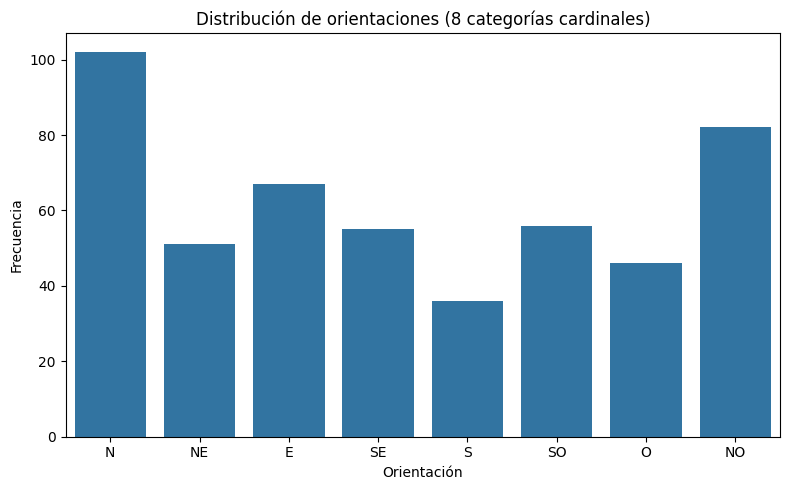

In [8]:
# ==================== Crear variable orientacion_cat8 (8 direcciones cardinales) ====================
import pandas as pd
import numpy as np

# Si no tienes el DataFrame cargado:
df = pd.read_csv("bbdd/ifn3_ifn4.csv")

# Asegurar tipo numérico
df['orientacion'] = pd.to_numeric(df['orientacion'], errors='coerce')

# Normalizar valores (por si hay negativos o >360)
df['orientacion'] = df['orientacion'] % 360

# Función de clasificación (8 direcciones, centro en cada múltiplo de 45°)
def clasificar_orientacion_8(o):
    if pd.isna(o):
        return np.nan
    if (o >= 337.5) or (o < 22.5):
        return 'N'   # Norte
    elif 22.5 <= o < 67.5:
        return 'NE'  # Noreste
    elif 67.5 <= o < 112.5:
        return 'E'   # Este
    elif 112.5 <= o < 157.5:
        return 'SE'  # Sureste
    elif 157.5 <= o < 202.5:
        return 'S'   # Sur
    elif 202.5 <= o < 247.5:
        return 'SO'  # Suroeste
    elif 247.5 <= o < 292.5:
        return 'O'   # Oeste
    else:
        return 'NO'  # Noroeste

# Aplicar la función
df['orientacion_cat'] = df['orientacion'].apply(clasificar_orientacion_8)

# Mostrar resultados
print("✅ Variable 'orientacion_cat' (8 categorías) creada correctamente.\n")
print(df['orientacion_cat'].value_counts(dropna=False))

# Visualización rápida
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.countplot(x='orientacion_cat', data=df, order=['N','NE','E','SE','S','SO','O','NO'])
plt.title("Distribución de orientaciones (8 categorías cardinales)")
plt.xlabel("Orientación")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

# (Opcional) Guardar con la nueva columna
df.to_csv("bbdd/ifn3_ifn4.csv", index=False)


✅ Variable 'orientacion_cat' (8 categorías) creada correctamente.

orientacion_cat
NaN    15160
Name: count, dtype: int64


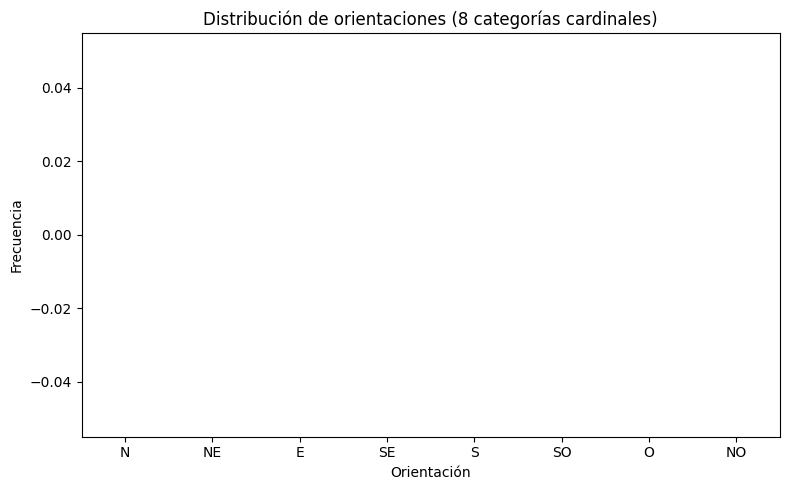

In [9]:
# ==================== Crear variable orientacion_cat8 (8 direcciones cardinales) ====================
import pandas as pd
import numpy as np

# Si no tienes el DataFrame cargado:
df = pd.read_csv("bbdd/ifn2_ifn4.csv")

# Asegurar tipo numérico
df['orientacion'] = pd.to_numeric(df['orientacion'], errors='coerce')

# Normalizar valores (por si hay negativos o >360)
df['orientacion'] = df['orientacion'] % 360

# Función de clasificación (8 direcciones, centro en cada múltiplo de 45°)
def clasificar_orientacion_8(o):
    if pd.isna(o):
        return np.nan
    if (o >= 337.5) or (o < 22.5):
        return 'N'   # Norte
    elif 22.5 <= o < 67.5:
        return 'NE'  # Noreste
    elif 67.5 <= o < 112.5:
        return 'E'   # Este
    elif 112.5 <= o < 157.5:
        return 'SE'  # Sureste
    elif 157.5 <= o < 202.5:
        return 'S'   # Sur
    elif 202.5 <= o < 247.5:
        return 'SO'  # Suroeste
    elif 247.5 <= o < 292.5:
        return 'O'   # Oeste
    else:
        return 'NO'  # Noroeste

# Aplicar la función
df['orientacion_cat'] = df['orientacion'].apply(clasificar_orientacion_8)

# Mostrar resultados
print("✅ Variable 'orientacion_cat' (8 categorías) creada correctamente.\n")
print(df['orientacion_cat'].value_counts(dropna=False))

# Visualización rápida
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.countplot(x='orientacion_cat', data=df, order=['N','NE','E','SE','S','SO','O','NO'])
plt.title("Distribución de orientaciones (8 categorías cardinales)")
plt.xlabel("Orientación")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

# (Opcional) Guardar con la nueva columna
df.to_csv("bbdd/ifn2_ifn4.csv", index=False)


----------------------------
PENDIENTE: categorizar

In [10]:
# ==================== CREAR pendiente_cat BASADA EN DATOS REALES ====================
import pandas as pd
from pathlib import Path

archivos = [
    "bbdd/ifn3_ifn4.csv",
    "bbdd/ifn2_ifn4.csv",
]

# Rango adaptado a tus percentiles (usando grados)
bins = [-1, 5, 10, 15, 20, 30, 50, 100]
labels = [
    "muy suave (<5°)",
    "suave (5-10°)",
    "moderada (10-15°)",
    "fuerte (15-20°)",
    "muy fuerte (20-30°)",
    "escarpada (30-50°)",
    "extrema (>50°)"
]

for ruta in archivos:
    path = Path(ruta)
    if not path.exists():
        print(f"⚠️ No se encuentra el archivo: {path}")
        continue

    print(f"\n📂 Procesando: {path.name}")
    df = pd.read_csv(path)

    if "pendiente" not in df.columns:
        print("⚠️ No existe la columna 'pendiente' en este archivo.")
        continue

    # Reemplazar -99 y valores negativos por NaN
    df.loc[df["pendiente"] < 0, "pendiente"] = pd.NA

    # Crear categorías
    df["pendiente_cat"] = pd.cut(
        df["pendiente"],
        bins=bins,
        labels=labels,
        include_lowest=True
    )

    # Mostrar resumen
    conteo = df["pendiente_cat"].value_counts(dropna=False)
    print("Distribución de pendiente_cat:")
    print(conteo)

    # Guardar CSV actualizado
    df.to_csv(path, index=False)
    print(f"💾 Archivo actualizado y guardado: {path.name}")

print("\n✅ pendiente_cat creada con rangos adaptados a los datos reales.")



📂 Procesando: ifn3_ifn4.csv


/tmp/ipykernel_3051937/2891466296.py:29: DtypeWarning: Columns (0: orientacion_cat) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)


Distribución de pendiente_cat:
pendiente_cat
NaN                    119369
suave (5-10°)             143
moderada (10-15°)         114
muy fuerte (20-30°)       104
fuerte (15-20°)            85
muy suave (<5°)            43
escarpada (30-50°)          6
extrema (>50°)              0
Name: count, dtype: int64


💾 Archivo actualizado y guardado: ifn3_ifn4.csv

📂 Procesando: ifn2_ifn4.csv
Distribución de pendiente_cat:
pendiente_cat
NaN                    15160
muy suave (<5°)            0
suave (5-10°)              0
moderada (10-15°)          0
fuerte (15-20°)            0
muy fuerte (20-30°)        0
escarpada (30-50°)         0
extrema (>50°)             0
Name: count, dtype: int64


💾 Archivo actualizado y guardado: ifn2_ifn4.csv

✅ pendiente_cat creada con rangos adaptados a los datos reales.


INF2 - IFN3 - IFN4

In [11]:
# -*- coding: utf-8 -*-
import pandas as pd
import numpy as np

# ==== Rutas ====
ruta_ifn2 = "bbdd/ifn2_ifn4.csv"
ruta_ifn3 = "bbdd/ifn3_ifn4.csv"
ruta_out  = "bbdd/ifn_entrenamiento.csv"

# ==== Columnas finales (en el orden solicitado) ====
final_cols = [
    "ifn_id","idparcela_especie","parcela_id","especie_id","tipo_especie","grupo_id","ocupa",
    "estado_id","fpmasa_id","tratmasa_id","orgmasa1_id","tipsuelo1_id","tipsuelo2_id","tipsuelo3_id",
    "rocosidad_id","radio","orientacion","orientacion_cat","elevacion","pendiente","pendiente_cat","martonneidx_id","ano","nivel1_id",
    "nivel2_id","merosiva_id","textura_id","matorg_id","modcomb_id","disesp_id","comesp_id","fccarb",
    "fcctot","carbono_bruto3",
    "npies_1","npies_2","npies_5","npies_10","npies_15","npies_20","npies_25","npies_30","npies_35",
    "npies_40","npies_45","npies_50","npies_55","npies_60","npies_65","npies_70",
    "ano4","cr4","c4","carbono_bruto4","periodo",
    "evi_max_invierno","evi_max_otoño","evi_max_primavera","evi_max_verano",
    "evi_mean_invierno","evi_mean_otoño","evi_mean_primavera","evi_mean_verano",
    "evi_median_invierno","evi_median_otoño","evi_median_primavera","evi_median_verano",
    "evi_min_invierno","evi_min_otoño","evi_min_primavera","evi_min_verano",
    "evi_std_invierno","evi_std_otoño","evi_std_primavera","evi_std_verano",
    "gndvi_max_invierno","gndvi_max_otoño","gndvi_max_primavera","gndvi_max_verano",
    "gndvi_mean_invierno","gndvi_mean_otoño","gndvi_mean_primavera","gndvi_mean_verano",
    "gndvi_median_invierno","gndvi_median_otoño","gndvi_median_primavera","gndvi_median_verano",
    "gndvi_min_invierno","gndvi_min_otoño","gndvi_min_primavera","gndvi_min_verano",
    "gndvi_std_invierno","gndvi_std_otoño","gndvi_std_primavera","gndvi_std_verano",
    "ndii_max_invierno","ndii_max_otoño","ndii_max_primavera","ndii_max_verano",
    "ndii_mean_invierno","ndii_mean_otoño","ndii_mean_primavera","ndii_mean_verano",
    "ndii_median_invierno","ndii_median_otoño","ndii_median_primavera","ndii_median_verano",
    "ndii_min_invierno","ndii_min_otoño","ndii_min_primavera","ndii_min_verano",
    "ndii_std_invierno","ndii_std_otoño","ndii_std_primavera","ndii_std_verano",
    "ndvi_max_invierno","ndvi_max_otoño","ndvi_max_primavera","ndvi_max_verano",
    "ndvi_mean_invierno","ndvi_mean_otoño","ndvi_mean_primavera","ndvi_mean_verano",
    "ndvi_median_invierno","ndvi_median_otoño","ndvi_median_primavera","ndvi_median_verano",
    "ndvi_min_invierno","ndvi_min_otoño","ndvi_min_primavera","ndvi_min_verano",
    "ndvi_std_invierno","ndvi_std_otoño","ndvi_std_primavera","ndvi_std_verano",
    "pr_max_invierno","pr_max_otoño","pr_max_primavera","pr_max_verano",
    "pr_mean_invierno","pr_mean_otoño","pr_mean_primavera","pr_mean_verano",
    "pr_min_invierno","pr_min_otoño","pr_min_primavera","pr_min_verano",
    "pr_std_invierno","pr_std_otoño","pr_std_primavera","pr_std_verano",
    "pr_sum_invierno","pr_sum_otoño","pr_sum_primavera","pr_sum_verano",
    "skt_max_invierno","skt_max_otoño","skt_max_primavera","skt_max_verano",
    "skt_max_max_invierno","skt_max_max_otoño","skt_max_max_primavera","skt_max_max_verano",
    "skt_max_mean_invierno","skt_max_mean_otoño","skt_max_mean_primavera","skt_max_mean_verano",
    "skt_max_min_invierno","skt_max_min_otoño","skt_max_min_primavera","skt_max_min_verano",
    "skt_max_std_invierno","skt_max_std_otoño","skt_max_std_primavera","skt_max_std_verano",
    "skt_mean_invierno","skt_mean_otoño","skt_mean_primavera","skt_mean_verano",
    "skt_min_invierno","skt_min_otoño","skt_min_primavera","skt_min_verano",
    "skt_min_max_invierno","skt_min_max_otoño","skt_min_max_primavera","skt_min_max_verano",
    "skt_min_mean_invierno","skt_min_mean_otoño","skt_min_mean_primavera","skt_min_mean_verano",
    "skt_min_min_invierno","skt_min_min_otoño","skt_min_min_primavera","skt_min_min_verano",
    "skt_min_std_invierno","skt_min_std_otoño","skt_min_std_primavera","skt_min_std_verano",
    "skt_std_invierno","skt_std_otoño","skt_std_primavera","skt_std_verano",
    "stl1_max_invierno","stl1_max_otoño","stl1_max_primavera","stl1_max_verano",
    "stl1_max_max_invierno","stl1_max_max_otoño","stl1_max_max_primavera","stl1_max_max_verano",
    "stl1_max_mean_invierno","stl1_max_mean_otoño","stl1_max_mean_primavera","stl1_max_mean_verano",
    "stl1_max_min_invierno","stl1_max_min_otoño","stl1_max_min_primavera","stl1_max_min_verano",
    "stl1_max_std_invierno","stl1_max_std_otoño","stl1_max_std_primavera","stl1_max_std_verano",
    "stl1_mean_invierno","stl1_mean_otoño","stl1_mean_primavera","stl1_mean_verano",
    "stl1_min_invierno","stl1_min_otoño","stl1_min_primavera","stl1_min_verano",
    "stl1_min_max_invierno","stl1_min_max_otoño","stl1_min_max_primavera","stl1_min_max_verano",
    "stl1_min_mean_invierno","stl1_min_mean_otoño","stl1_min_mean_primavera","stl1_min_mean_verano",
    "stl1_min_min_invierno","stl1_min_min_otoño","stl1_min_min_primavera","stl1_min_min_verano",
    "stl1_min_std_invierno","stl1_min_std_otoño","stl1_min_std_primavera","stl1_min_std_verano",
    "stl1_std_invierno","stl1_std_otoño","stl1_std_primavera","stl1_std_verano",
    "stl2_max_invierno","stl2_max_otoño","stl2_max_primavera","stl2_max_verano",
    "stl2_max_max_invierno","stl2_max_max_otoño","stl2_max_max_primavera","stl2_max_max_verano",
    "stl2_max_mean_invierno","stl2_max_mean_otoño","stl2_max_mean_primavera","stl2_max_mean_verano",
    "stl2_max_min_invierno","stl2_max_min_otoño","stl2_max_min_primavera","stl2_max_min_verano",
    "stl2_max_std_invierno","stl2_max_std_otoño","stl2_max_std_primavera","stl2_max_std_verano",
    "stl2_mean_invierno","stl2_mean_otoño","stl2_mean_primavera","stl2_mean_verano",
    "stl2_min_invierno","stl2_min_otoño","stl2_min_primavera","stl2_min_verano",
    "stl2_min_max_invierno","stl2_min_max_otoño","stl2_min_max_primavera","stl2_min_max_verano",
    "stl2_min_mean_invierno","stl2_min_mean_otoño","stl2_min_mean_primavera","stl2_min_mean_verano",
    "stl2_min_min_invierno","stl2_min_min_otoño","stl2_min_min_primavera","stl2_min_min_verano",
    "stl2_min_std_invierno","stl2_min_std_otoño","stl2_min_std_primavera","stl2_min_std_verano",
    "stl2_std_invierno","stl2_std_otoño","stl2_std_primavera","stl2_std_verano",
    "stl3_max_invierno","stl3_max_otoño","stl3_max_primavera","stl3_max_verano",
    "stl3_max_max_invierno","stl3_max_max_otoño","stl3_max_max_primavera","stl3_max_max_verano",
    "stl3_max_mean_invierno","stl3_max_mean_otoño","stl3_max_mean_primavera","stl3_max_mean_verano",
    "stl3_max_min_invierno","stl3_max_min_otoño","stl3_max_min_primavera","stl3_max_min_verano",
    "stl3_max_std_invierno","stl3_max_std_otoño","stl3_max_std_primavera","stl3_max_std_verano",
    "stl3_mean_invierno","stl3_mean_otoño","stl3_mean_primavera","stl3_mean_verano",
    "stl3_min_invierno","stl3_min_otoño","stl3_min_primavera","stl3_min_verano",
    "stl3_min_max_invierno","stl3_min_max_otoño","stl3_min_max_primavera","stl3_min_max_verano",
    "stl3_min_mean_invierno","stl3_min_mean_otoño","stl3_min_mean_primavera","stl3_min_mean_verano",
    "stl3_min_min_invierno","stl3_min_min_otoño","stl3_min_min_primavera","stl3_min_min_verano",
    "stl3_min_std_invierno","stl3_min_std_otoño","stl3_min_std_primavera","stl3_min_std_verano",
    "stl3_std_invierno","stl3_std_otoño","stl3_std_primavera","stl3_std_verano",
    "stl4_max_invierno","stl4_max_otoño","stl4_max_primavera","stl4_max_verano",
    "stl4_max_max_invierno","stl4_max_max_otoño","stl4_max_max_primavera","stl4_max_max_verano",
    "stl4_max_mean_invierno","stl4_max_mean_otoño","stl4_max_mean_primavera","stl4_max_mean_verano",
    "stl4_max_min_invierno","stl4_max_min_otoño","stl4_max_min_primavera","stl4_max_min_verano",
    "stl4_max_std_invierno","stl4_max_std_otoño","stl4_max_std_primavera","stl4_max_std_verano",
    "stl4_mean_invierno","stl4_mean_otoño","stl4_mean_primavera","stl4_mean_verano",
    "stl4_min_invierno","stl4_min_otoño","stl4_min_primavera","stl4_min_verano",
    "stl4_min_max_invierno","stl4_min_max_otoño","stl4_min_max_primavera","stl4_min_max_verano",
    "stl4_min_mean_invierno","stl4_min_mean_otoño","stl4_min_mean_primavera","stl4_min_mean_verano",
    "stl4_min_min_invierno","stl4_min_min_otoño","stl4_min_min_primavera","stl4_min_min_verano",
    "stl4_min_std_invierno","stl4_min_std_otoño","stl4_min_std_primavera","stl4_min_std_verano",
    "stl4_std_invierno","stl4_std_otoño","stl4_std_primavera","stl4_std_verano",
    "t2m_max_invierno","t2m_max_otoño","t2m_max_primavera","t2m_max_verano",
    "t2m_max_max_invierno","t2m_max_max_otoño","t2m_max_max_primavera","t2m_max_max_verano",
    "t2m_max_mean_invierno","t2m_max_mean_otoño","t2m_max_mean_primavera","t2m_max_mean_verano",
    "t2m_max_min_invierno","t2m_max_min_otoño","t2m_max_min_primavera","t2m_max_min_verano",
    "t2m_max_std_invierno","t2m_max_std_otoño","t2m_max_std_primavera","t2m_max_std_verano",
    "t2m_mean_invierno","t2m_mean_otoño","t2m_mean_primavera","t2m_mean_verano",
    "t2m_min_invierno","t2m_min_otoño","t2m_min_primavera","t2m_min_verano",
    "t2m_min_max_invierno","t2m_min_max_otoño","t2m_min_max_primavera","t2m_min_max_verano",
    "t2m_min_mean_invierno","t2m_min_mean_otoño","t2m_min_mean_primavera","t2m_min_mean_verano",
    "t2m_min_min_invierno","t2m_min_min_otoño","t2m_min_min_primavera","t2m_min_min_verano",
    "t2m_min_std_invierno","t2m_min_std_otoño","t2m_min_std_primavera","t2m_min_std_verano",
    "t2m_std_invierno","t2m_std_otoño","t2m_std_primavera","t2m_std_verano",
    "c","carbono_bruto"
]

# ==== Lectura (añade sep=';' si procede) ====
df2 = pd.read_csv(ruta_ifn2)
df3 = pd.read_csv(ruta_ifn3)

# ==== Funciones auxiliares ====
def add_missing_columns(df, columns):
    """Añade columnas faltantes con NaN sin modificar las existentes."""
    missing = [c for c in columns if c not in df.columns]
    for c in missing:
        df[c] = np.nan
    return df

def build_block_ifn2(df):
    df = df.copy()
    df["ifn_id"] = 2
    # Derivadas según origen:
    df["ano"] = df.get("ano2")
    df["c"] = df.get("c2")
    df["carbono_bruto"] = df.get("carbono_bruto2")
    # npies_1, npies_2, npies_5 no existen en ifn2 -> NaN (se mantienen si existieran)
    for col in ["npies_1","npies_2","npies_5"]:
        if col not in df.columns:
            df[col] = np.nan
    # Campos exclusivos de IFN3 que no están en IFN2:
    for col in ["fpmasa_id","tratmasa_id","orgmasa1_id","nivel1_id","nivel2_id","fccarb","fcctot","carbono_bruto3","npies_35","npies_40","npies_45","npies_50","npies_55","npies_60","npies_65","npies_70"]:
        if col not in df.columns:
            df[col] = np.nan
    return df

def build_block_ifn3(df):
    df = df.copy()
    df["ifn_id"] = 3
    # Derivadas según origen:
    df["ano"] = df.get("ano3")
    df["c"] = df.get("c3")
    df["carbono_bruto"] = df.get("carbono_bruto3")
    # IFN3 suele tener npies_1, _2, _5… si faltan, crea NaN
    for col in ["npies_1","npies_2","npies_5","npies_10","npies_15","npies_20","npies_25","npies_30","npies_35","npies_40","npies_45","npies_50","npies_55","npies_60","npies_65","npies_70"]:
        if col not in df.columns:
            df[col] = np.nan
    return df

# ==== Preparar bloques según origen ====
df2b = build_block_ifn2(df2)
df3b = build_block_ifn3(df3)

# ==== Asegurar todas las columnas finales (agregar faltantes) ====
df2b = add_missing_columns(df2b, final_cols)
df3b = add_missing_columns(df3b, final_cols)

# ==== Unificar y reordenar ====
unificado = pd.concat([df2b[final_cols], df3b[final_cols]], axis=0, ignore_index=True)

# ==== Guardar (añade sep=';' si procede) ====
unificado.to_csv(ruta_out, index=False)

print(f"Filas IFN2: {len(df2b)}")
print(f"Filas IFN3: {len(df3b)}")
print(f"Filas unificadas: {len(unificado)}")
print(f"Guardado en: {ruta_out}")


/tmp/ipykernel_3051937/3410373981.py:122: DtypeWarning: Columns (0: orientacion_cat, 1: pendiente_cat) have mixed types. Specify dtype option on import or set low_memory=False.
  df3 = pd.read_csv(ruta_ifn3)
/tmp/ipykernel_3051937/3410373981.py:129: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[c] = np.nan
/tmp/ipykernel_3051937/3410373981.py:129: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[c] = np.nan
/tmp/ipykernel_3051937/3410373981.py:129: PerformanceWarning: DataFrame is highly fragmented.  This is usually the resul

/tmp/ipykernel_3051937/3410373981.py:129: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[c] = np.nan
/tmp/ipykernel_3051937/3410373981.py:129: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[c] = np.nan
/tmp/ipykernel_3051937/3410373981.py:129: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[c] =

Filas IFN2: 15160
Filas IFN3: 119864
Filas unificadas: 135024
Guardado en: bbdd/ifn_entrenamiento.csv


Filtros y conteo

-----------------------------
PERIODO: agrupar

In [12]:
import pandas as pd

# ==============================
# 1) Cargar datos
# ==============================
ruta = "bbdd/ifn_entrenamiento.csv"
df = pd.read_csv(ruta)

# ==============================
# 2) Crear variable agrupada
# ==============================

def agrupar_periodo(p):
    if p < 6:
        return 5
    elif 7 <= p <= 10:
        return 10
    elif 18 <= p <= 21:
        return 20
    elif p >= 29:
        return 30
    else:
        return p  # Mantener valores fuera de los intervalos definidos

df["periodo_agrupado"] = df["periodo"].apply(agrupar_periodo)

# ==============================
# 3) Guardar resultado
# ==============================
df.to_csv("bbdd/ifn_entrenamiento.csv", index=False)

print("✔ Variable 'periodo_agrupado' creada y guardada correctamente.")
print(df[["periodo", "periodo_agrupado"]].head(20))

/tmp/ipykernel_3051937/2857042439.py:7: DtypeWarning: Columns (0: orientacion_cat, 1: pendiente_cat) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(ruta)
/tmp/ipykernel_3051937/2857042439.py:25: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["periodo_agrupado"] = df["periodo"].apply(agrupar_periodo)


✔ Variable 'periodo_agrupado' creada y guardada correctamente.
    periodo  periodo_agrupado
0      24.0              24.0
1      24.0              24.0
2       NaN               NaN
3       NaN               NaN
4       NaN               NaN
5      24.0              24.0
6      24.0              24.0
7      24.0              24.0
8      24.0              24.0
9      24.0              24.0
10      NaN               NaN
11      NaN               NaN
12      NaN               NaN
13     25.0              25.0
14      NaN               NaN
15      NaN               NaN
16      NaN               NaN
17      NaN               NaN
18     26.0              26.0
19      NaN               NaN


/tmp/ipykernel_3051937/2299389486.py:10: DtypeWarning: Columns (0: orientacion_cat, 1: pendiente_cat) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(ruta)


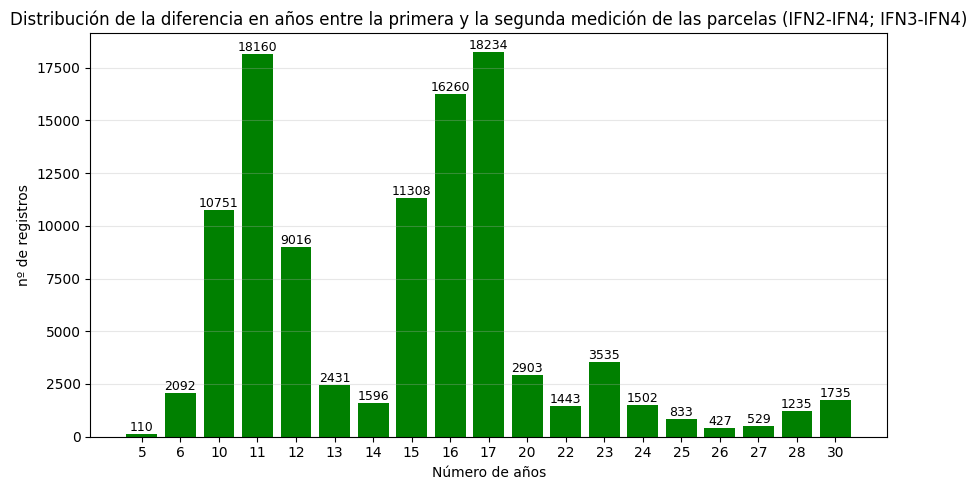

In [13]:
# -*- coding: utf-8 -*-
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ruta al CSV
ruta = "bbdd/ifn_entrenamiento.csv"

# Cargar datos
df = pd.read_csv(ruta)

if 'periodo_agrupado' not in df.columns:
    raise KeyError("La columna 'periodo_agrupado' no existe en el CSV.")

# Convertir a numérico, eliminar NaN y castear a entero
periodo_agrupado = pd.to_numeric(df['periodo_agrupado'], errors='coerce').dropna().astype(int)

# Conteos por periodo_agrupado ordenados
counts = periodo_agrupado.value_counts().sort_index()

# Gráfico de barras (color verde)
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(counts.index.astype(str), counts.values, color='green')

# Etiquetas y formato
ax.set_xlabel("Número de años")
ax.set_ylabel("nº de registros")
ax.set_title("Distribución de la diferencia en años entre la primera y la segunda medición de las parcelas (IFN2-IFN4; IFN3-IFN4)")
ax.grid(axis='y', alpha=0.3)

# Anotar valores encima de cada barra
for x, v in zip(counts.index.astype(str), counts.values):
    ax.text(x, v, f"{v}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


In [14]:
import pandas as pd

# Cargar dataset
df = pd.read_csv("bbdd/ifn_entrenamiento.csv")

# ===============================
# Conteos de c4
# ===============================

c4_nulos = df['c4'].isna().sum()
c4_no_nulos = df['c4'].notna().sum()

# ===============================
# Conteos de carbono_bruto4
# ===============================

cb4_nulos = df['carbono_bruto4'].isna().sum()
cb4_no_nulos = df['carbono_bruto4'].notna().sum()

# ===============================
# Mostrar resultados
# ===============================

print("=== Conteo de valores nulos / no nulos ===\n")
print(f"c4 nulo:     {c4_nulos}")
print(f"c4 no nulo:  {c4_no_nulos}\n")

print(f"carbono_bruto4 nulo:     {cb4_nulos}")
print(f"carbono_bruto4 no nulo:  {cb4_no_nulos}")


=== Conteo de valores nulos / no nulos ===

c4 nulo:     35073
c4 no nulo:  99951

carbono_bruto4 nulo:     35073
carbono_bruto4 no nulo:  99951


/tmp/ipykernel_3051937/3020328817.py:4: DtypeWarning: Columns (0: orientacion_cat, 1: pendiente_cat) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("bbdd/ifn_entrenamiento.csv")
